[ 7.         20.33333333]
    gene  control  treated    log2FC
0  BRCA1        5        9  0.847997
1   TP53       20       19 -0.074001


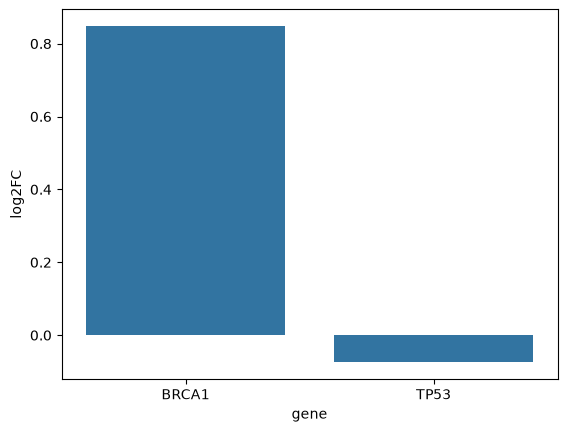

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# NumPy: fast arrays
expr = np.array([[5, 7, 9], [20, 22, 19]])
print(expr.mean(axis=1))

# pandas: tables
df = pd.DataFrame({"gene": ["BRCA1", "TP53"], "control": [5, 20], "treated": [9, 19]})
df["log2FC"] = np.log2(df["treated"] / df["control"])
print(df)

# seaborn: plots
sns.barplot(data=df, x="gene", y="log2FC")
plt.savefig("log2fc.png", dpi=150)

5 hits; 3 after filtering
sseqid
NM_000546.6       1
NM_001126112.3    1
XM_005256691.4    1
dtype: int64


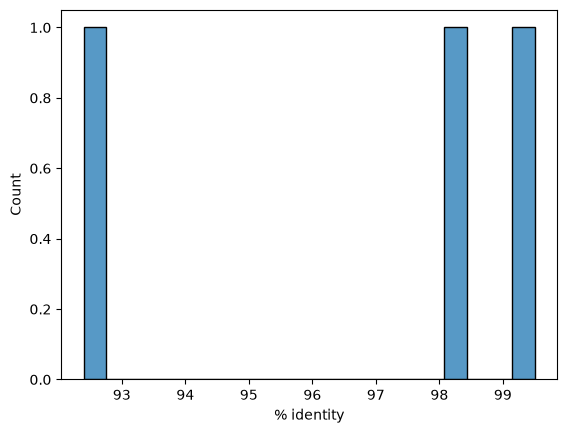

In [2]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
cols = "qseqid sseqid pident length mismatch gapopen qstart qend sstart send evalue bitscore".split()
hits = pd.read_csv("hits.tsv", sep="\t", header=None, names=cols)
good = hits[(hits.pident >= 90) & (hits.evalue <= 1e-10)]
print(len(hits), "hits;", len(good), "after filtering")
print(good.groupby("sseqid").size().sort_values(ascending=False).head())
sns.histplot(good.pident, bins=20); plt.xlabel("% identity"); plt.savefig("pident.png", dpi=150)